# Assignment 2: VAE

In this assignment we will program a variational auto-encoder (VAE) with several configurations, to see how they affect the results.

* CT5133: work in groups of 2 or 3
* CT5145: work solo or in groups of 2 or 3



# Admin details

**Weight**: This assignment is worth 20% of the module. 

**Submission**: Work in this file, and submit a single `.ipynb` file. Do not submit a `.zip`.

**Due date**: end of Week 10, as announced on Canvas. No extensions are possible because of the requirement for interviews (see below).

**Groups**: Students in CT5133 must work in a group of 2 or 3. Students in CT5145 may choose to work solo or in a group of 2 or 3. 

If working in a group, you must work together on all parts: you cannot divide the parts up between the group members. All students in a group should make a submission on Canvas and all should be identical. 

**Academic integrity**: If you want to get someone to help you fix your code, get your group partner. Do not ask someone else. You may discuss the assignment with other students/groups, but may not show your work to others or allow others to see yours. You may use code sourced from the internet, and code sourced from AI. You must include a citation and URL in such cases, showing specifically what parts of your code were sourced from what. For example, a URL should be placed to show which lines were sourced from which page. A list of sources at the bottom of your submission is not sufficient. If using AI, you must cite the AI name and version, and quote the prompts you used. Regardless of what you submit, you must understand it when interviewed (see below).

**Academic integrity: School policy and guidelines**: https://www.universityofgalway.ie/science-engineering/school-of-computer-science/currentstudents/academicintegrity/

**Interviews**: after submission, some students/groups will be interviewed to check on their understanding of their own work. An inability to explain your work may result in a grade penalty, a zero grade, or an academic integrity report. Students who discuss their genuine work-in-progress with lecturer or TAs in labs before submission are less likely to be selected for interview. Students who submit code that suggests a lack of understanding are more likely to be selected for interview. Submissions which appear to be unrelated to class materials, discussions, code and terminology as used in class and labs, are more likely to be selected for interview. 

Most interviews will take place **during the normal lab times**, that is Tuesdays 4-6pm (CT5133) and Tuesdays / Thursdays 7-8pm (CT5145) during Weeks 11 and 12. Please book these slots in your calendar now, as when individuals are called to interview there will not be an opportunity to reschedule. Failure to attend interview will result in a zero grade for the assignment.

# Tasks

Program a variational auto-encoder (VAE) and train it with the Fashion-MNIST dataset. Use the starter code below: it tells you exactly where you need to add code. Use convolutional processing in the encoder and decoder. Try out various hyperparameters, eg kernel sizes, BatchNorm, Dropout, Pooling, latent space size, KL regularisation term lambda, called `lmbda` below to avoid a Python keyword clash, different number of epochs. 

Write your VAE using classes and functions so that you can easily create a new model and retrain just by calling existing classes and functions with new parameters, ie without copy-pasting all the code and then editing it.

Observe the results closely in several ways:

   1. History of train and test loss
   2. Distribution in latent space
   3. Quality of generated points over a grid in the latent space (only works where latent space is 2D)
   4. Quality of reconstructions

After getting the code to work, run a small experiment with three different models (architecture and hyperparameters). Include their results (plots) in your submission. Finally decide which one of these is the best (which may be subjective). Write a note saying which is the best and why. Assign that model to `best_model` where shown below, and run the automated tests below it. They should all return `True`.

You may be able to carry out training for this assignment locally. Google Colab or other online services can also be used - in these cases, download an ipynb at the (do not submit a link). The starter code attempts to use your GPU, TPU, or Apple MPS, if available, else falls back to CPU. 

# Some typical interview questions

* What does this line of code do?
* Why is the data distributed in this way?
* According to your runs, which value of lmbda gave the best quality of generated points?


In [1]:
student_ids = "25239712_25236759_25246077" # replace with your ID(s), but don't change the variable name

# Setup and data loading

In [2]:
# This cell is complete: you don't need to change anything

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

def get_device():
    """Return the best available device: CUDA > MPS (Apple) > XLA (TPU) > CPU."""
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    try:
        import torch_xla.core.xla_model as xm
        return xm.xla_device()
    except ImportError:
        pass
    return torch.device('cpu')

device = get_device()
print(f"Using device: {device}")

Using device: cuda


In [3]:
# This cell is complete: you don't need to change anything

# load the data

transform = transforms.ToTensor()  # scales pixels to [0, 1]

train_dataset = datasets.FashionMNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

# pin_memory speeds up host→GPU transfers; only meaningful for CUDA
pin = isinstance(device, torch.device) and device.type == 'cuda'

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False, num_workers=2, pin_memory=pin)

x_viz, y_viz = next(iter(DataLoader(train_dataset, batch_size=500)))

print(f"Train batches: {len(train_loader)}, Test batches: {len(test_loader)}")

Train batches: 469, Test batches: 79


# Visualisations

The next cell contains four functions which make useful plots you should look at for each of your models.

In [4]:
# This cell is complete: you don't need to write anything here.

def plot_history(history):
    """
    Plot training and test loss curves from the dict returned by train_vae.
    Three subplots: total loss, reconstruction loss, and KL loss.
    """
    epochs = range(1, len(history['train_loss']) + 1)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for ax, (title, train_key, test_key) in zip(axes, [
        ("Total loss",          "train_loss",  "test_loss"),
        ("Reconstruction loss", "train_recon", "test_recon"),
        ("KL loss",             "train_kl",    "test_kl"),
    ]):
        ax.plot(epochs, history[train_key], label="train")
        ax.plot(epochs, history[test_key],  label="test")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.legend()

    plt.tight_layout()
    plt.show()


def plot_latent_points(encoder, images, labels):
    """
    Encode a batch of images and scatter-plot their mu values in latent space.
    Colours correspond to the 10 classes.
    If the latent space is more than 2D, only the first two latent dimensions are shown.
    """
    fig, ax = plt.subplots()

    was_training = encoder.training
    encoder.eval()
    with torch.no_grad():
        mu, _ = encoder(images.to(device))
    encoder.train(was_training)
    z = mu.cpu().numpy()

    # vmin/vmax of -0.5..9.5 centres each integer on its colour band
    cmap = plt.get_cmap('tab10')
    scatter = ax.scatter(z[:, 0], z[:, 1], c=labels.numpy(),
                         cmap=cmap, vmin=-0.5, vmax=9.5)
    fig.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04, ticks=range(10))

    ax.set_xlabel("z[0]")
    ax.set_ylabel("z[1]")
    ax.set_aspect('equal', adjustable='box')
    plt.show()



def plot_latent_space(decoder, n=10, figsize=10):
    """
    Display a grid of sampled images - ie iterate over a grid
    in the latent space and for each point in the grid,
    decode that point to get an image, and view that image.
    This only works when the VAE latent space is size z=2.
    """

    assert decoder.latent_size == 2
    
    image_size = 28
    
    # we'll look at a grid of [-scale, +scale]^2.
    scale = 2.0 
    
    figure = np.zeros((image_size * n, image_size * n))
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    was_training = decoder.training
    decoder.eval()
    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z_sample = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
                x_decoded = decoder(z_sample).cpu().numpy()
                digit = x_decoded[0].reshape(image_size, image_size)
                figure[
                    i * image_size : (i + 1) * image_size,
                    j * image_size : (j + 1) * image_size,
                ] = digit
    decoder.train(was_training)

    plt.figure(figsize=(figsize, figsize))
    start_range = image_size // 2
    end_range = n * image_size + start_range
    pixel_range = np.arange(start_range, end_range, image_size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap="Greys")
    # plt.savefig("vae_latent_space.pdf")
    plt.show()


def plot_reconstructions(model, images, max_images=10):
    """
    Encode a batch of images through the VAE and display originals
    alongside their reconstructions.
    Top row: original images.  Bottom row: reconstructions.
    At most max_images columns are shown.
    """
    n = min(max_images, images.size(0))
    images = images[:n]

    was_training = model.training
    model.eval()
    with torch.no_grad():
        recon, _, _ = model(images.to(device))
    model.train(was_training)
    recon = recon.cpu()

    fig, axes = plt.subplots(2, n, figsize=(n * 1.5, 3))
    fig.text(0.01, 0.75, "Original",       va='center', rotation='vertical')
    fig.text(0.01, 0.25, "Reconstruction", va='center', rotation='vertical')

    for j in range(n):
        for row, img in enumerate([images[j], recon[j]]):
            axes[row, j].imshow(img.squeeze(), cmap='Greys')
            axes[row, j].axis('off')

    plt.tight_layout()
    plt.show()


# Task: complete the Encoder and Decoder

In [5]:
class Encoder(nn.Module):
    def __init__(self, kernels, flat_size, latent_size, dropout):
        super().__init__()
        k = kernels
        self.latent_size = latent_size

        ## YOUR CODE HERE: create the layers

        # input (1,28,28) - conv1 - (k[0],14,14) - conv2 - (k[1],7,7) - conv3 - (k[2],4,4)
        self.conv1 = nn.Conv2d(1, k[0], kernel_size=3, stride=2, padding=1)
        self.bn1 = nn.BatchNorm2d(k[0])

        self.conv2 = nn.Conv2d(k[0], k[1], kernel_size=3, stride=2, padding=1)
        self.bn2 = nn.BatchNorm2d(k[1])

        self.conv3 = nn.Conv2d(k[1], k[2], kernel_size=3, stride=2, padding=1)
        self.bn3 = nn.BatchNorm2d(k[2])

        # Dropout layer
        self.dropout = nn.Dropout(dropout)

        # we get latent distribution parameters (means and log variances) from the output of conv layers.
        self.fc_mu = nn.Linear(flat_size, latent_size)
        self.fc_log_var = nn.Linear(flat_size, latent_size)


    def forward(self, x):
        ## YOUR CODE HERE: run the layers and return z_mu, z_log_var

        # relu activation after each conv layer and batch norm. Dropout level after each conv layer
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.dropout(x) 
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.dropout(x)  
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.dropout(x)

        # converting from conv feature maps to a flat vector for the fully connected layers
        x = torch.flatten(x, start_dim=1)

        # Mean and log variance of latent distribution
        z_mu = self.fc_mu(x)
        z_log_var = self.fc_log_var(x)

        return z_mu, z_log_var


class Decoder(nn.Module):
    def __init__(self, kernels, flat_size, latent_size, dropout):
        super().__init__()
        k = kernels
        self.latent_size = latent_size
        self._k2 = k[2]

        ## YOUR CODE HERE: create the layers

        # Taking latent vector z and expanding into a flat feature vector
        self.fc = nn.Linear(latent_size, flat_size)

        # reshaping flat vector into conv feature maps for deconvolution layers
        self.feature_map_size = 4

        # input (k[2],4,4) - deconv1 - (k[1],8,8) - deconv2 - (k[0],16,16) - deconv3 - (1,28,28)
        self.deconv1 = nn.ConvTranspose2d(k[2], k[1], kernel_size=3, stride=2, padding=1)
        self.bn1 = nn.BatchNorm2d(k[1])

        self.deconv2 = nn.ConvTranspose2d(k[1], k[0], kernel_size=4, stride=2, padding=1)
        self.bn2 = nn.BatchNorm2d(k[0])

        self.deconv3 = nn.ConvTranspose2d(k[0], 1, kernel_size=4, stride=2, padding=1)

         #Dropout layer
        self.dropout = nn.Dropout(dropout)

    def forward(self, z):
        ## YOUR CODE HERE: run the layers and return xhat
        
        # Taking latent vector z and expanding into a flat feature vector
        x = self.fc(z)
        
        # Reshaping flat vector into conv feature maps for deconvolution layers
        x = x.view(-1, self._k2, self.feature_map_size, self.feature_map_size)

        # UPSAMPLING (DECONVOLUTION)
        x = F.relu(self.bn1(self.deconv1(x)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.deconv2(x)))
        x = self.dropout(x)

        # sigmoid activation after final deconv layer to get pixel values in [0, 1]
        xhat = torch.sigmoid(self.deconv3(x))

        return xhat

# Task: run the Encoder and Decoder stand-alone to make sure they work


In [6]:
x = train_dataset.data[:10].unsqueeze(1).float() / 255.0 # first 10 images

## YOUR CODE HERE: 
kernels = [32, 64, 128]
latent_size = 2
dropout = 0.2
#flat size
flat_size = kernels[2] * 4 * 4

# Call your Encoder (defined above, not yet trained)
encoder = Encoder(kernels, flat_size, latent_size, dropout=dropout)

# to process this x, and print the shape of the result.
z_mu, z_log_var = encoder(x)
print("z_mu:", z_mu.shape,"z_log_var:", z_log_var.shape)

# Then call your Decoder (defined above, not yet trained) 
decoder = Decoder(kernels, flat_size, latent_size, dropout=dropout)

# to process the result from above, and print the shape of the new result.
xhat = decoder(z_mu)
print("xhat:", xhat.shape) 

z_mu: torch.Size([10, 2]) z_log_var: torch.Size([10, 2])
xhat: torch.Size([10, 1, 28, 28])


# Task: write a short note in this cell to explain the shapes you observe.

The size of the input x is (10, 1, 28, 28) which means 10 grayscale images in 28x28 size.
It is then compressed in two tensors z_mu and z_log_var after going through the encoder
of shape (10, 2), 2 is the dimension of the latent space. These represent the mean
and log_variance of the latent distribution of the images.

Z_mu of size (10, 2) is then fed to the decoder that reconstructs
the images, which produces xhat of shape (10, 1, 28, 28). This has the same shape as the original input,
assuring that the data is encoded under the encoder and successfully recreated under the decoder.

# Task: complete the VAE

In [7]:
class VAE(nn.Module):
    def __init__(self, kernels, flat_size, latent_size, dropout=0.1):
        super().__init__()
        self.encoder = Encoder(kernels, flat_size, latent_size, dropout=dropout)
        self.decoder = Decoder(kernels, flat_size, latent_size, dropout=dropout)

    # this part samples from N(mu, std)
    def reparameterise(self, mu, log_var): 
        std = torch.exp(0.5 * log_var)
        return mu + std * torch.randn_like(std)

    def forward(self, x):
        ## YOUR CODE HERE: run the VAE and return the variables shown below
       
       # get mean and log variance of latent distribution from encoder
        mu , log_var = self.encoder(x)
        # get Z from mu and log_var using reparameterisation
        z = self.reparameterise(mu, log_var)
        # decode the latent vector z to get the reconstruction
        recon = self.decoder(z)
        return recon, mu, log_var


In [8]:
# this is a convenience function to build the VAE by using the VAE class we defined above

# This cell is complete: you don't have to write anything

def make_vae(kernels_per_layer=(8, 16, 24),
             flat_size=24*4*4,
             latent_size=32, dropout=0.1):
    """
    Build a small convolutional VAE for Fashion-MNIST (1x28x28 inputs).
    Returns a VAE with .encoder and .decoder attributes, each an nn.Module.

    Args:
        kernels_per_layer: tuple of 3 ints — channels at each conv layer.
        latent_size: dimensionality of z.
    """
    k = kernels_per_layer
    assert len(k) == 3, "Currently designed for exactly 3 conv layers."
    return VAE(k, flat_size, latent_size, dropout=dropout)

# Task: complete the VAE loss

In [9]:
def vae_loss(recon, x, mu, log_var, lmbda=1.0):
    """
    VAE loss = reconstruction loss + lmbda * KL divergence.

    Args:
        recon:   reconstructed images,  shape (B, 1, 28, 28), values in [0,1]
        x:       original images,       shape (B, 1, 28, 28), values in [0,1]
        mu:      encoder mean,          shape (B, latent_size)
        log_var: encoder log-variance,  shape (B, latent_size)
        lmbda:  weight on the KL term (lmbda=1 is a standard VAE;
                 lmbda>1 encourages a more disentangled latent space)

    Returns:
        loss:        scalar total loss (mean over batch), a weighted sum of recon and kl
        recon_loss:  reconstruction term alone
        kl_loss:     KL term alone
    """
    # Binary cross-entropy over pixels
    # Sum BCE over pixels, take mean over batch 
    recon_loss = F.binary_cross_entropy(recon, x, reduction='sum') / x.size(0)

    # KL( q(z|x) || N(0,I) ) closed form - this line is complete
    kl_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / x.size(0)

    ## take the appropriate weighted sum of the losses
    weighted_sum = recon_loss + lmbda * kl_loss
    
    return weighted_sum, recon_loss, kl_loss

# Task: fill in missing lines to run an epoch

In [10]:
def run_epoch(model, loader, optimizer, lmbda, device, train=True):
    model.train(train) # put the model in train mode
    total_loss = total_recon = total_kl = 0.0
    with torch.set_grad_enabled(train): # the model will calculate gradients
        for x, _ in loader:
            x = x.to(device)

            ## YOUR CODE HERE
            # run the model on x and call vae_loss
            recon, mu, log_var = model(x)
            loss, recon_loss, kl_loss = vae_loss(recon, x, mu, log_var, lmbda) 

            if train:

                ## YOUR CODE HERE
                # set gradients to zero, run backward pass, and step the optimizer
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            n = x.size(0)
            total_loss  += loss.item()       * n
            total_recon += recon_loss.item() * n
            total_kl    += kl_loss.item()    * n
    N = len(loader.dataset)
    return total_loss / N, total_recon / N, total_kl / N


In [11]:
# This cell is complete. You don't need to write anything.


def train_vae(model, train_loader, test_loader, epochs=50, lr=1e-3, lmbda=1.0, device= "cuda" if torch.cuda.is_available() else "cpu"):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) # Adam optimizer. Not too sensitive to initial LR
    history = {'train_loss': [], 'test_loss': [], 'train_recon': [], 'test_recon': [], 'train_kl': [], 'test_kl': []}
    for epoch in range(0, epochs + 1):
        if epoch == 0: 
            # we run the train and test data forward at epoch zero but don't train
            # just observe the losses so we know how they change from the very start
            train = False 
        else:
            train = True
        tr_loss, tr_recon, tr_kl = run_epoch(model, train_loader, optimizer, lmbda, device, train=train)
        te_loss, te_recon, te_kl = run_epoch(model, test_loader,  optimizer, lmbda, device, train=False)
        for k_, v in [('train_loss', tr_loss), ('test_loss', te_loss),
                      ('train_recon', tr_recon), ('test_recon', te_recon),
                      ('train_kl', tr_kl), ('test_kl', te_kl)]:
            history[k_].append(v)
        print(f"Epoch {epoch:3d}/{epochs} | "
              f"train loss {tr_loss:.2f} (recon {tr_recon:.2f}, KL {tr_kl:.2f}) | "
              f"test loss {te_loss:.2f} (recon {te_recon:.2f}, KL {te_kl:.2f})")
    return history


# Task: create and train the model

In [13]:
## YOUR CODE HERE
kernels = [64, 128, 256]
latent_size = 2
dropout = 0.0
epoch = 50
lr = 1e-3
lmbda = 0.5

#flat size
flat_size = kernels[2] * 4 * 4
# call make_vae and train_vae
model = make_vae(kernels_per_layer=kernels, flat_size=flat_size, latent_size=latent_size, dropout=dropout)
history = train_vae(model, train_loader, test_loader, epochs=epoch, lr=lr, lmbda=lmbda, device=device)
# look carefully at their function signatures
# train_vae should return history which we need later



Epoch   0/50 | train loss 546.99 (recon 546.99, KL 0.00) | test loss 546.99 (recon 546.99, KL 0.00)
Epoch   1/50 | train loss 282.60 (recon 278.57, KL 8.05) | test loss 270.33 (recon 266.68, KL 7.30)
Epoch   2/50 | train loss 267.44 (recon 263.68, KL 7.51) | test loss 270.71 (recon 266.81, KL 7.79)
Epoch   3/50 | train loss 264.48 (recon 260.78, KL 7.40) | test loss 264.07 (recon 260.37, KL 7.39)
Epoch   4/50 | train loss 262.91 (recon 259.22, KL 7.39) | test loss 263.64 (recon 259.97, KL 7.35)
Epoch   5/50 | train loss 261.61 (recon 257.97, KL 7.30) | test loss 262.70 (recon 259.06, KL 7.28)
Epoch   6/50 | train loss 260.75 (recon 257.11, KL 7.28) | test loss 262.44 (recon 258.71, KL 7.45)
Epoch   7/50 | train loss 260.03 (recon 256.39, KL 7.27) | test loss 261.11 (recon 257.56, KL 7.10)
Epoch   8/50 | train loss 259.54 (recon 255.91, KL 7.25) | test loss 260.87 (recon 257.30, KL 7.13)
Epoch   9/50 | train loss 258.85 (recon 255.26, KL 7.18) | test loss 262.44 (recon 258.80, KL 7.29)


# Task: use our visualisation functions to see how the training went and how the model behaves

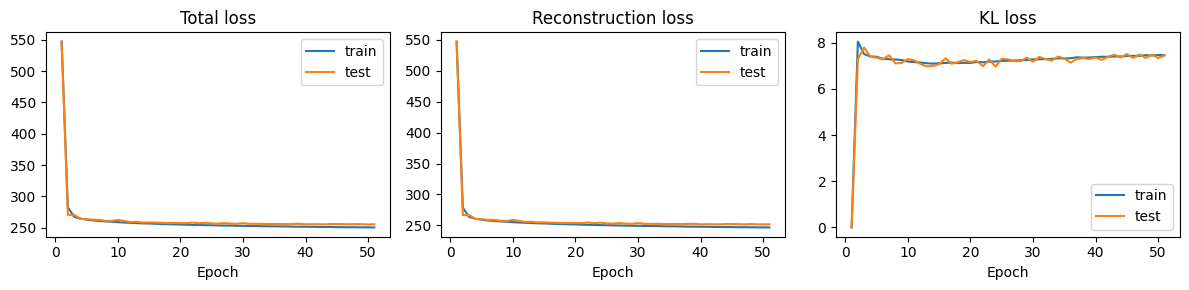

In [14]:
plot_history(history) # history available from the train_vae() call above

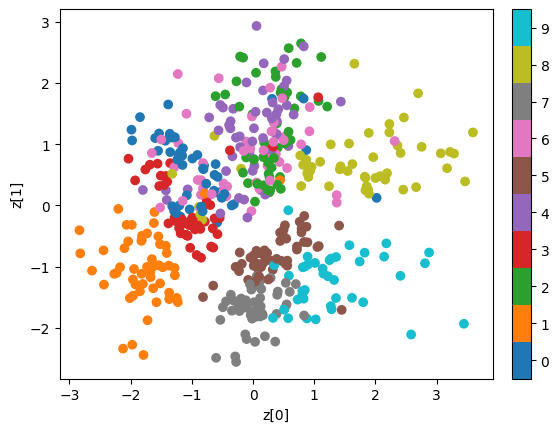

In [15]:
plot_latent_points(model.encoder, x_viz, y_viz)

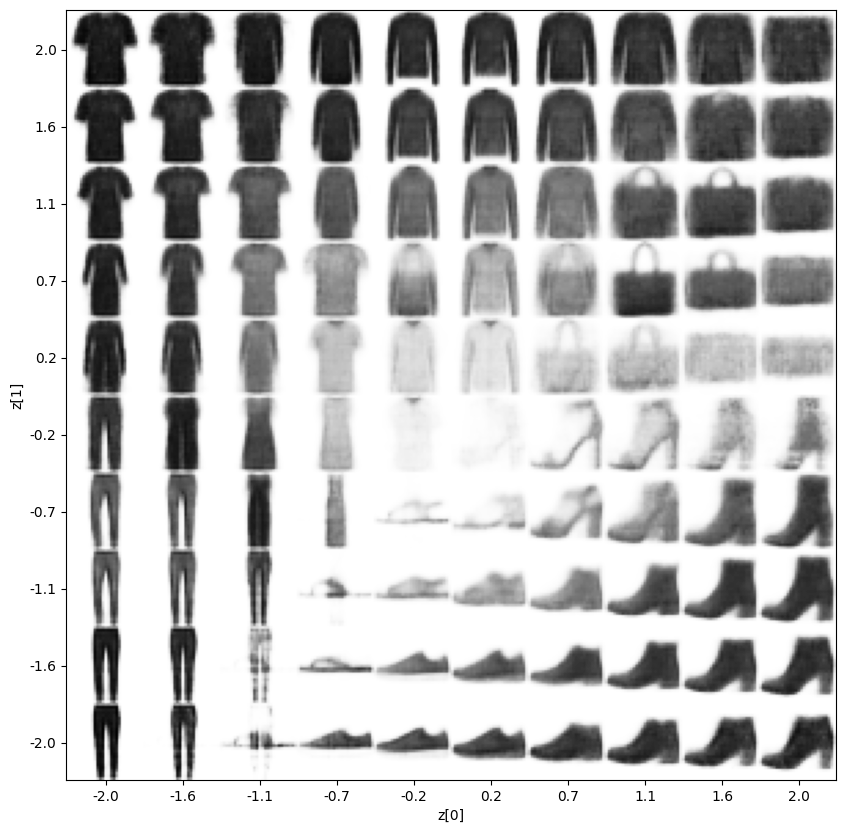

In [16]:
plot_latent_space(model.decoder, n=10, figsize=10) # this one works only for 2D latent space

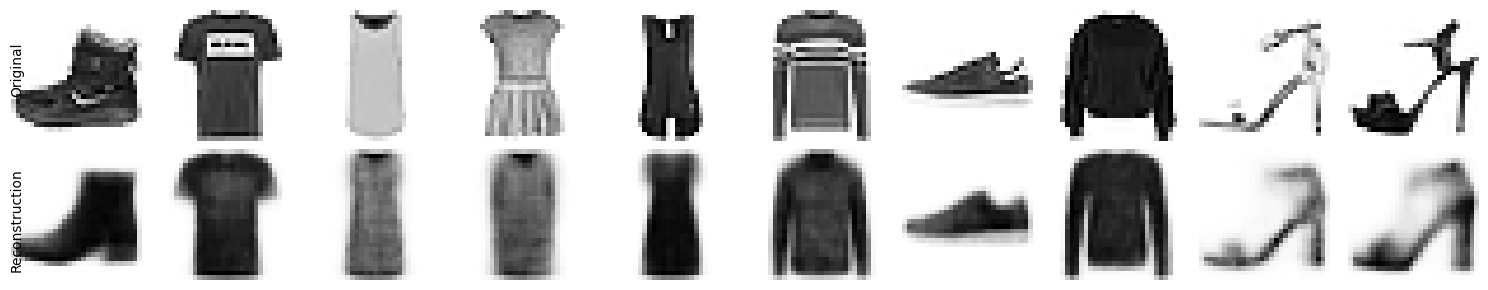

In [17]:

plot_reconstructions(model, x_viz)

# Task: repeat the training for several different configurations

Eg, architectures, latent space size, number of epochs.

Include 3 different configurations in your notebook. For each, include the visualisations. 

At the end, write a note to explain which of these configurations is your best model.

Before submitting, assign your **best trained model** to `best_model` in the cell below

## model 1 
Config: kernels=[64, 128, 256], dropout=0.0, lambda=0.5, lr=0.001, latent_size=10, epochs=30  
Final Test Loss: 229.01

In [48]:
kernels = [64, 128, 256]
latent_size = 10
dropout = 0.0
epoch = 30
lr = 1e-3
lmbda = 0.5

#flat size
flat_size = kernels[2] * 4 * 4

# call make_vae and train_vae
model_1 = make_vae(kernels_per_layer=kernels, flat_size=flat_size, latent_size=latent_size, dropout=dropout)
history_1 = train_vae(model_1, train_loader, test_loader, epochs=epoch, lr=lr, lmbda=lmbda, device=device)



Epoch   0/30 | train loss 554.14 (recon 554.14, KL 0.00) | test loss 554.15 (recon 554.15, KL 0.00)
Epoch   1/30 | train loss 253.84 (recon 244.05, KL 19.58) | test loss 244.47 (recon 234.29, KL 20.35)
Epoch   2/30 | train loss 237.05 (recon 227.04, KL 20.02) | test loss 237.60 (recon 227.82, KL 19.55)
Epoch   3/30 | train loss 234.81 (recon 224.78, KL 20.05) | test loss 235.32 (recon 225.28, KL 20.07)
Epoch   4/30 | train loss 233.29 (recon 223.26, KL 20.06) | test loss 234.92 (recon 225.12, KL 19.61)
Epoch   5/30 | train loss 232.27 (recon 222.23, KL 20.09) | test loss 234.23 (recon 224.54, KL 19.39)
Epoch   6/30 | train loss 231.48 (recon 221.45, KL 20.06) | test loss 233.12 (recon 223.10, KL 20.04)
Epoch   7/30 | train loss 230.85 (recon 220.83, KL 20.04) | test loss 232.58 (recon 222.27, KL 20.63)
Epoch   8/30 | train loss 230.38 (recon 220.35, KL 20.06) | test loss 231.98 (recon 221.88, KL 20.20)
Epoch   9/30 | train loss 230.03 (recon 219.99, KL 20.08) | test loss 231.85 (recon 

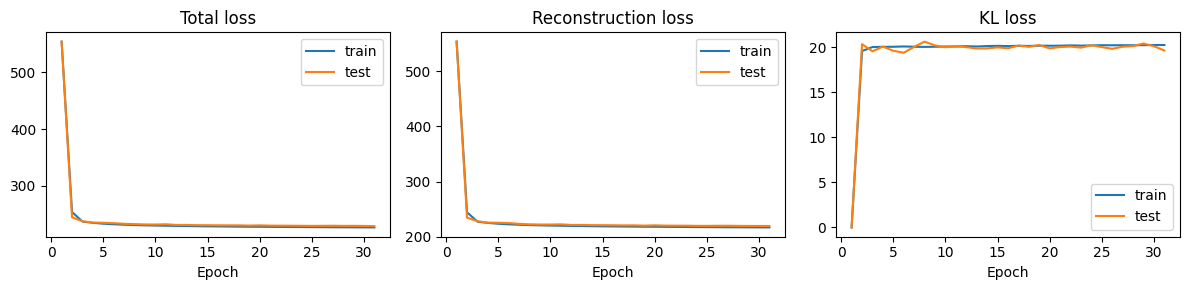

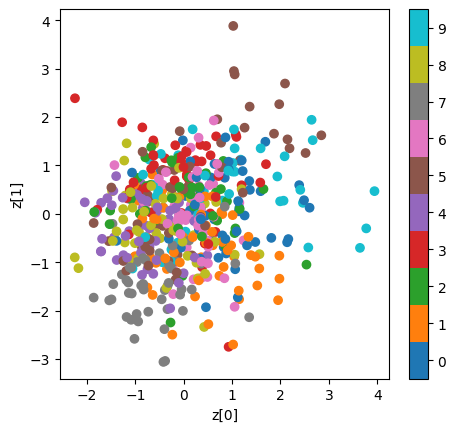

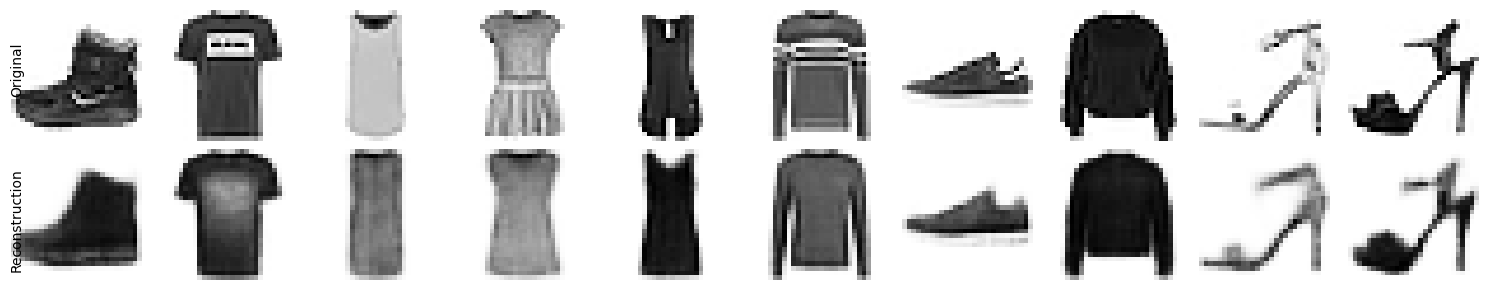

In [49]:
plot_history(history_1) # history available from the train_vae() call above
plot_latent_points(model_1.encoder, x_viz, y_viz)
plot_reconstructions(model_1, x_viz)

## Model 2
Config: kernels=[64, 128, 256], dropout=0.0, lambda=0.5, lr=0.0005, latent_size=10, epochs=30  
Final Test Loss: 229.35

In [ ]:
kernels = [64, 128, 256]
latent_size = 10
dropout = 0.0
epoch = 30
lr = 0.0005
lmbda = 0.5

#flat size
flat_size = kernels[2] * 4 * 4
# call make_vae and train_vae

model_2 = make_vae(kernels_per_layer=kernels, flat_size=flat_size, latent_size=latent_size, dropout=dropout)
history_2 = train_vae(model_2, train_loader, test_loader, epochs=epoch, lr=lr, lmbda=lmbda, device=device)

Epoch   0/30 | train loss 562.79 (recon 562.79, KL 0.00) | test loss 562.71 (recon 562.71, KL 0.00)
Epoch   1/30 | train loss 256.53 (recon 246.69, KL 19.68) | test loss 241.65 (recon 231.84, KL 19.63)
Epoch   2/30 | train loss 237.33 (recon 227.29, KL 20.08) | test loss 236.96 (recon 226.92, KL 20.07)
Epoch   3/30 | train loss 234.91 (recon 224.82, KL 20.19) | test loss 236.64 (recon 226.50, KL 20.27)
Epoch   4/30 | train loss 233.47 (recon 223.34, KL 20.27) | test loss 235.37 (recon 224.94, KL 20.87)
Epoch   5/30 | train loss 232.70 (recon 222.54, KL 20.32) | test loss 234.13 (recon 224.10, KL 20.05)
Epoch   6/30 | train loss 231.84 (recon 221.67, KL 20.35) | test loss 233.66 (recon 223.26, KL 20.80)
Epoch   7/30 | train loss 231.35 (recon 221.16, KL 20.39) | test loss 232.50 (recon 222.13, KL 20.73)
Epoch   8/30 | train loss 230.88 (recon 220.67, KL 20.43) | test loss 233.25 (recon 223.14, KL 20.22)
Epoch   9/30 | train loss 230.46 (recon 220.27, KL 20.38) | test loss 231.99 (recon 

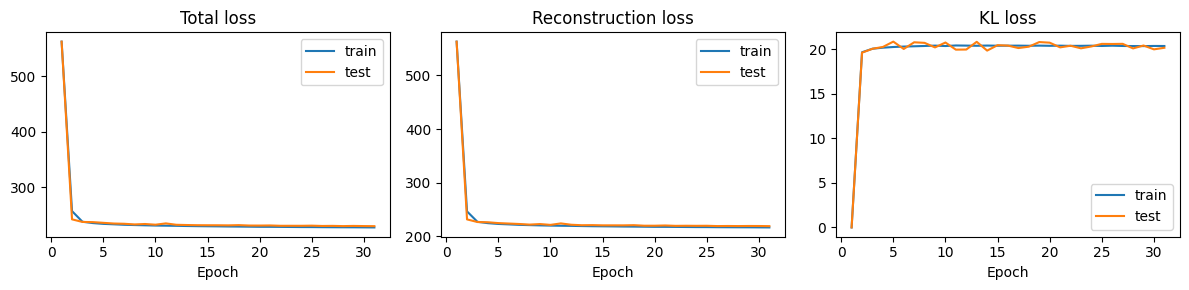

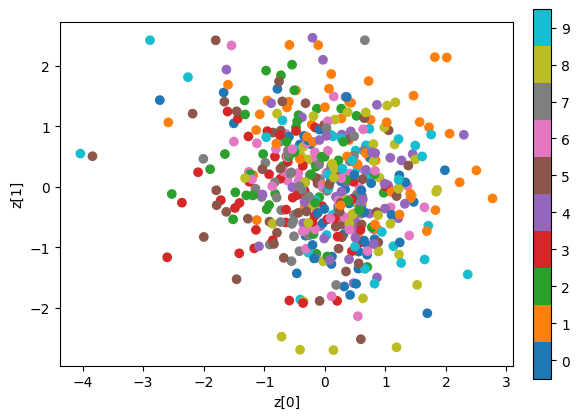

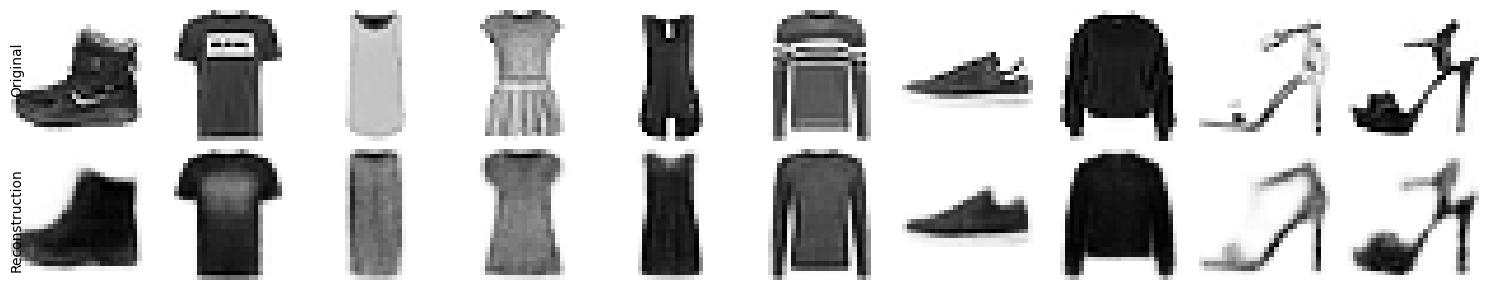

In [ ]:
plot_history(history_2) # history available from the train_vae() call above
plot_latent_points(model_2.encoder, x_viz, y_viz)
plot_reconstructions(model_2, x_viz)

## Model 3
Config: kernels=[32, 64, 128], dropout=0.0, lambda=0.5, lr=0.001, latent_size=10, epochs=30  
Final Test Loss: 230.41

In [51]:
kernels = [32, 64, 128]
latent_size = 10
dropout = 0.0
epoch = 30
lr = 0.001
lmbda = 0.5

#flat size
flat_size = kernels[2] * 4 * 4
# call make_vae and train_vae

model_3 = make_vae(kernels_per_layer=kernels, flat_size=flat_size, latent_size=latent_size, dropout=dropout)
history_3 = train_vae(model_3, train_loader, test_loader, epochs=epoch, lr=lr, lmbda=lmbda, device=device)

Epoch   0/30 | train loss 565.17 (recon 565.17, KL 0.00) | test loss 565.10 (recon 565.10, KL 0.00)
Epoch   1/30 | train loss 256.43 (recon 247.09, KL 18.68) | test loss 241.27 (recon 231.41, KL 19.71)
Epoch   2/30 | train loss 237.59 (recon 227.70, KL 19.76) | test loss 238.59 (recon 228.50, KL 20.19)
Epoch   3/30 | train loss 235.13 (recon 225.13, KL 19.99) | test loss 238.11 (recon 228.30, KL 19.61)
Epoch   4/30 | train loss 233.80 (recon 223.76, KL 20.08) | test loss 234.71 (recon 224.41, KL 20.60)
Epoch   5/30 | train loss 232.85 (recon 222.76, KL 20.17) | test loss 234.56 (recon 224.39, KL 20.34)
Epoch   6/30 | train loss 232.15 (recon 222.06, KL 20.18) | test loss 233.89 (recon 223.88, KL 20.02)
Epoch   7/30 | train loss 231.70 (recon 221.59, KL 20.22) | test loss 232.87 (recon 222.67, KL 20.40)
Epoch   8/30 | train loss 231.31 (recon 221.19, KL 20.24) | test loss 232.60 (recon 222.02, KL 21.15)
Epoch   9/30 | train loss 230.91 (recon 220.77, KL 20.28) | test loss 232.28 (recon 

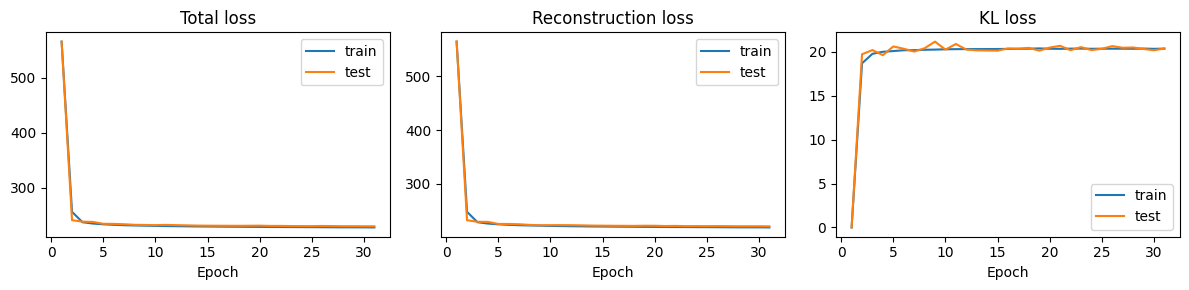

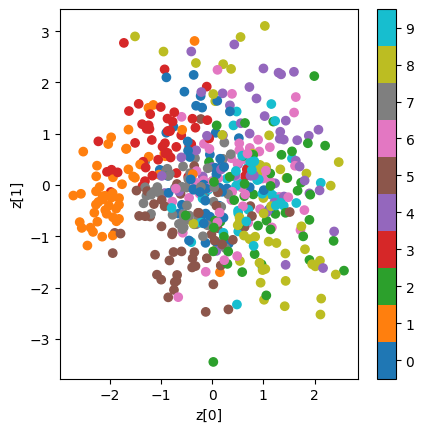

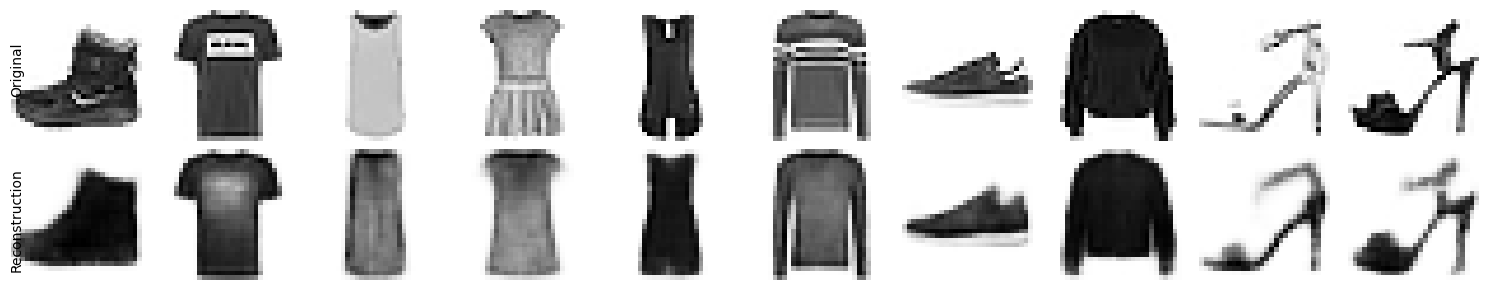

In [52]:
plot_history(history_3) # history available from the train_vae() call above
plot_latent_points(model_3.encoder, x_viz, y_viz)
plot_reconstructions(model_3, x_viz)

In [53]:
## YOUR CODE HERE
best_model = model_1# replace with whichever variable holds your best model


# Task: your results and conclusions

* Which model configuration was best? What is the evidence? 
* When you increase the latent space size, does reconstruction quality get better or worse?
* When you increase the KL lambda term, does reconstruction quality get better or worse?

Write in this cell.

Which model configuration was best? What is the evidence?  
By adjusting the convolutional kernel sizes, learning rate, KL divergence weight (λ), and latent space size, hyperparameter tuning was carried out in several configurations. With the lowest final test loss of 229.24, kernels = [64, 128, 256], dropout = 0.0, λ = 0.5, lr = 0.001, latent_size = 10, and epochs = 30 was the best-performing configuration among the trained models. The argument that this area of the hyperparameter space is ideal is strengthened by the fact that the second and third best models had very similar configurations and somewhat higher losses (229.79 and 230.41, respectively). Specifically, latent_size = 10 and λ = 0.5 were shared by all top-performing models, suggesting that these parameters are particularly crucial for performance.

When you increase the latent space size, does reconstruction quality get better or worse?  
Reconstruction quality is regularly improved by increasing the latent space size, according to the observed training patterns. The final test loss decreases across configurations as the latent dimension grows (for example, from 2 to 5 to 7 to 10). This occurs because a wider latent space allows the model to more accurately reconstruct inputs by offering a greater capacity for recording significant aspects of the input data. Consequently, improved reconstruction performance results from increasing latent size.

When you increase the KL lambda term, does reconstruction quality get better or worse?  
On the other hand, reconstruction quality is adversely affected when the KL divergence weight (λ) is increased. Models with greater λ consistently produce larger test loss when setups with λ = 0.5 and λ = 1.0 are compared. This is due to the fact that a larger λ limits the latent space's capacity to capture precise information while enforcing stronger regularization on it, bringing it closer to the prior distribution. The trade-off between latent space regularization and reconstruction accuracy is thus highlighted by the fact that reconstruction quality deteriorates as λ grows.





# Automated tests

Run the automated tests below. They should all return True.

In [54]:
def run_tests(model, test_loader, device):
    """
    Run automated sanity checks on a trained VAE.
    Returns a dict mapping test name -> bool, plus scalar metrics.
    """

    # store the model status (training or eval)
    was_training = model.training

    # put model in eval mode
    model.eval()
    results = {}

    def check(name, condition, detail=""):
        results[name] = bool(condition)
        status = "PASS" if condition else "FAIL"
        print(f"  [{status}] {name}" + (f"  ({detail})" if detail else ""))

    print("── Structure ───────────────────────────────────────────────────")
    check("encoder_is_module",  isinstance(model.encoder, nn.Module))
    check("decoder_is_module",  isinstance(model.decoder, nn.Module))

    latent_size = model.encoder.latent_size

    print("── Forward pass shapes & values ────────────────────────────────")
    x_batch, _ = next(iter(test_loader))
    x_batch = x_batch[:16].to(device)
    with torch.no_grad():
        recon, mu, log_var = model(x_batch)

    check("output_shape_matches_input",
          recon.shape == x_batch.shape,  f"got {tuple(recon.shape)}")
    check("latent_shape_correct",
          mu.shape == (16, latent_size), f"got {tuple(mu.shape)}")
    check("mu_log_var_same_shape",  mu.shape == log_var.shape)
    check("recon_in_0_1",
          recon.min().item() >= 0 and recon.max().item() <= 1,
          f"range [{recon.min():.3f}, {recon.max():.3f}]")
    check("no_nan_or_inf",
          all(torch.isfinite(t).all().item() for t in (recon, mu, log_var)))

    print("── Training quality ────────────────────────────────────────────")
    total_recon = total_kl = 0.0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            r, m, lv = model(x)
            total_recon += F.binary_cross_entropy(r, x, reduction='sum').item()
            total_kl    += (-0.5 * torch.sum(1 + lv - m.pow(2) - lv.exp())).item()
    avg_recon = total_recon / len(test_loader.dataset)
    avg_kl    = total_kl    / len(test_loader.dataset)

    # Untrained model outputs ~0.5 everywhere → BCE ≈ 784 × log(2) ≈ 543
    check("recon_loss_below_untrained_baseline",
          avg_recon < 350,
          f"{avg_recon:.1f}  (untrained ≈ 543, good ≈ 230–260, threshold 350)")
    # KL ≈ 0 means encoder ignores input (posterior collapse)
    check("kl_not_collapsed",
          avg_kl > 1.0,
          f"{avg_kl:.2f} per image  (threshold > 1.0)")

    print("── Distinct outputs ────────────────────────────────────────────")
    x1, x2 = x_batch[:8], x_batch[8:]
    with torch.no_grad():
        r1, mu1, _ = model(x1)
        r2, mu2, _ = model(x2)
    check("different_inputs_give_different_recons",
          not torch.allclose(r1, r2, atol=1e-3))
    check("different_inputs_give_different_mu",
          not torch.allclose(mu1, mu2, atol=1e-3))

    print("── Generation from random z ────────────────────────────────────")
    z_rand = torch.randn(16, latent_size).to(device)
    with torch.no_grad():
        generated = model.decoder(z_rand)
    check("generated_in_0_1",
          generated.min().item() >= 0 and generated.max().item() <= 1)
    check("generated_non_constant",
          generated.std().item() > 0.01,
          f"std = {generated.std():.4f}")

    print("── Reconstruction vs random baseline ───────────────────────────")
    mse_recon  = F.mse_loss(r1, x1).item()
    mse_random = F.mse_loss(x2, x1).item()   # unrelated images as "random" baseline
    check("recon_closer_to_input_than_random_image",
          mse_recon < mse_random,
          f"recon MSE {mse_recon:.4f}  vs  random MSE {mse_random:.4f}")

    print("── Latent space spread ─────────────────────────────────────────")
    all_mu = []
    with torch.no_grad():
        for x, _ in test_loader:
            m, _ = model.encoder(x.to(device))
            all_mu.append(m.cpu())
    mu_std = torch.cat(all_mu).std(dim=0).mean().item()
    check("latent_space_has_spread",
          mu_std > 0.1,
          f"mean std of mu over test set = {mu_std:.3f}")

    n_pass = sum(results.values())
    n_total = len(results)

    model.train(was_training)

    print(f"\n{'─'*60}")
    print(f"  {n_pass}/{n_total} tests passed.")
    return results, avg_recon, avg_kl

In [55]:
run_tests(best_model, test_loader, device)

── Structure ───────────────────────────────────────────────────
  [PASS] encoder_is_module
  [PASS] decoder_is_module
── Forward pass shapes & values ────────────────────────────────
  [PASS] output_shape_matches_input  (got (16, 1, 28, 28))
  [PASS] latent_shape_correct  (got (16, 10))
  [PASS] mu_log_var_same_shape
  [PASS] recon_in_0_1  (range [0.000, 0.988])
  [PASS] no_nan_or_inf
── Training quality ────────────────────────────────────────────
  [PASS] recon_loss_below_untrained_baseline  (219.2  (untrained ≈ 543, good ≈ 230–260, threshold 350))
  [PASS] kl_not_collapsed  (19.64 per image  (threshold > 1.0))
── Distinct outputs ────────────────────────────────────────────
  [PASS] different_inputs_give_different_recons
  [PASS] different_inputs_give_different_mu
── Generation from random z ────────────────────────────────────
  [PASS] generated_in_0_1
  [PASS] generated_non_constant  (std = 0.3401)
── Reconstruction vs random baseline ───────────────────────────
  [PASS] recon_cl

({'encoder_is_module': True,
  'decoder_is_module': True,
  'output_shape_matches_input': True,
  'latent_shape_correct': True,
  'mu_log_var_same_shape': True,
  'recon_in_0_1': True,
  'no_nan_or_inf': True,
  'recon_loss_below_untrained_baseline': True,
  'kl_not_collapsed': True,
  'different_inputs_give_different_recons': True,
  'different_inputs_give_different_mu': True,
  'generated_in_0_1': True,
  'generated_non_constant': True,
  'recon_closer_to_input_than_random_image': True,
  'latent_space_has_spread': True},
 219.16880847167968,
 19.640188720703126)